## **Business Understanding**

**State of Art**

Breast cancer is a major cause of death among women. Detecting and treating it early greatly improves outcomes, but doctors can make mistakes. A computer based tool can support them by indicating whether a tumor is benign or malignant

In this project, we train an Artificial Neural Network (ANN) on measurements extracted from images of cell nuclei, in order to classify tumors as malignant or benign with high accuracy

**Business objective (BO)**

BO1: Distinguish benign from malignant breast tumors to support early cancer detection

BO2: Improve tumor classification performance by reducing misclassifications and increasing prediction accuracy

BO3: Help doctors prioritize patients by identifying high-risk cases and providing personalized recommendations for further medical investigation.

**Data Science objective (DSO)**

DSO1: Build an ANN classifier that separates benign from malignant tumors, detecting at least 95% of malignant cases

DSO2: Apply feature selection, model comparison, and hyperparameter tuning to improve classification performance and reduce false predictions

DSO3: Develop an intelligent recommendation model that analyzes tumor features, classification results, and risk scores to recommend relevant complementary medical examinations using machine learning and clinical guidelines

## **Data Aquisition and Understanding**

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

In [ ]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()
y = (data.target == 0).astype(int)
y.name = "maligne"

print("Nombre de patientes   :", X.shape[0])
print("Nombre de mesures  :", X.shape[1])

Nombre de patientes   : 569
Nombre de mesures  : 30


on a 596 patients et 30 mesures par patient

remarque : dans sicki_learn , la classe "maligne" est codéé en 0, on l'a inversé pour qu'elle sera 1 donc classe positive c'est la classe true qui est le cancer

In [ ]:
X.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


* controle qualité de donnés


In [ ]:

print("Valeurs manquantes :", X.isna().sum().sum())
print("Lignes en double                  :", X.duplicated().sum())
print("Colonnes qui ne changent jamais   :", (X.nunique() == 1).sum())
print("Valeurs négatives                 :", (X < 0).sum().sum())
print("Valeurs égales à zéro             :", (X == 0).sum().sum())


zeros_par_colonne = (X == 0).sum()
print("\nColonnes qui contiennent des zéros :")
print(zeros_par_colonne[zeros_par_colonne > 0])

Valeurs manquantes : 0
Lignes en double                  : 0
Colonnes qui ne changent jamais   : 0
Valeurs négatives                 : 0
Valeurs égales à zéro             : 78

Colonnes qui contiennent des zéros :
mean concavity          13
mean concave points     13
concavity error         13
concave points error    13
worst concavity         13
worst concave points    13
dtype: int64


les donnés sont propres , il n'ay ni des valeurs manquantes , ni doublons

il ya des colonnes qui ont des valeurs égales à 0 (78 valeurs), prnincipalement dans les colonnes concavité et points concaves

* etude de la valiable cible

Tumeurs bénignes : 357 -> 62.74 %
Tumeurs malignes : 212 -> 37.26 %

Un modèle qui répond toujours 'bénigne' a 62.74 % de bonnes réponses.


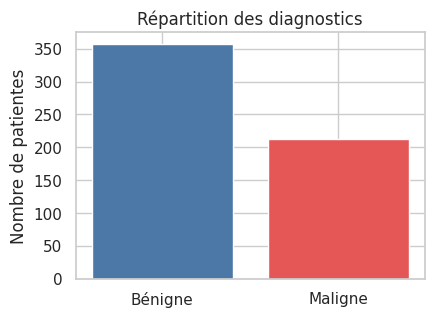

In [ ]:
nb_benignes = (y == 0).sum()
nb_malignes = (y == 1).sum()
total = len(y)

print("Tumeurs bénignes :", nb_benignes, "->", round(nb_benignes / total * 100, 2), "%")
print("Tumeurs malignes :", nb_malignes, "->", round(nb_malignes / total * 100, 2), "%")


print("\nUn modèle qui répond toujours 'bénigne' a", round(nb_benignes / total * 100, 2), "% de bonnes réponses.")

#Graphique
plt.figure(figsize=(4.5, 3.2))
plt.bar(["Bénigne", "Maligne"], [nb_benignes, nb_malignes], color=["#4C78A8", "#E45756"])
plt.ylabel("Nombre de patientes")
plt.title("Répartition des diagnostics")
plt.show()

357 tumeur benigne (62%) et 37.3% malignes, on remarque un désequilibre entre les classes

* etude d'echelle des variables

Les 5 plus PETITES moyennes :
fractal dimension error    0.0038
smoothness error           0.0070
concave points error       0.0118
symmetry error             0.0205
compactness error          0.0255
dtype: float64

Les 5 plus GRANDES moyennes :
area error          40.3
mean perimeter      92.0
worst perimeter    107.3
mean area          654.9
worst area         880.6
dtype: float64

La plus grande moyenne est environ 232044 fois plus grande que la plus petite.


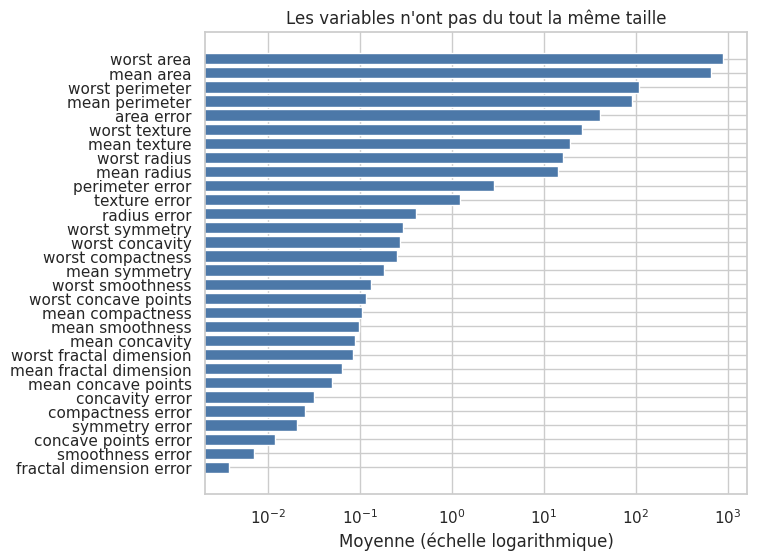

In [ ]:
moyennes = X.mean().sort_values()

print("Les 5 plus PETITES moyennes :")
print(moyennes.head(5).round(4))
print("\nLes 5 plus GRANDES moyennes :")
print(moyennes.tail(5).round(1))

rapport = moyennes.max() / moyennes.min()
print("\nLa plus grande moyenne est environ", round(rapport), "fois plus grande que la plus petite.")

# Graphique
plt.figure(figsize=(7, 6))
plt.barh(moyennes.index, moyennes.values, color="#4C78A8")
plt.xscale("log")
plt.xlabel("Moyenne (échelle logarithmique)")
plt.title("Les variables n'ont pas du tout la même taille")
plt.show()

les variables ont des unités differentes et ils ne sont pas sur la meme echelle

il faut les rendre sur la meme echelle, donc on va utiliser la standardisation

* outliers


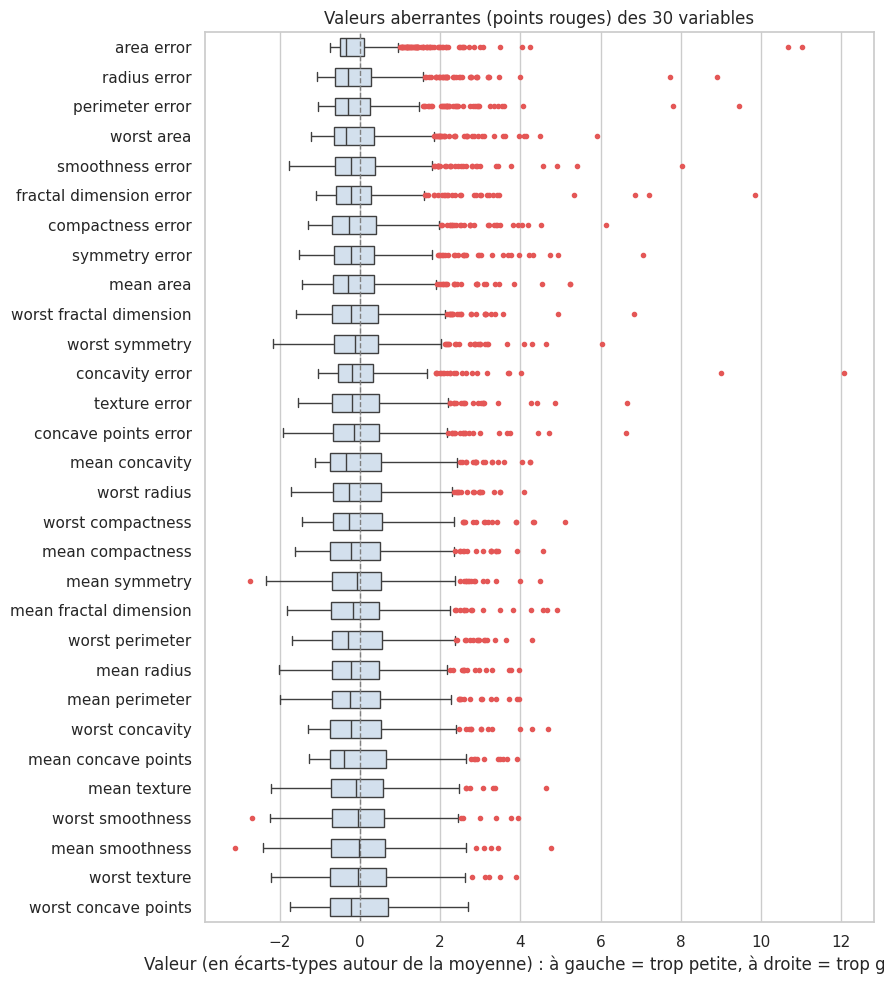

In [ ]:
# Valeurs aberrantes de TOUTES les variables sur un seul graphique
# On met toutes les variables sur la même échelle (centrées autour de 0) pour pouvoir les comparer
X_std = (X - X.mean()) / X.std()

Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
est_aberrante = (X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)
ordre = est_aberrante.sum().sort_values(ascending=False).index

plt.figure(figsize=(9, 10))
sns.boxplot(data=X_std[ordre], orient="h", color="#CFE0F1", width=0.6,
            flierprops=dict(marker="o", markerfacecolor="#E45756", markeredgecolor="#E45756", markersize=3))
plt.axvline(0, color="gray", linestyle="--", linewidth=1)
plt.xlabel("Valeur (en écarts-types autour de la moyenne) : à gauche = trop petite, à droite = trop grande")
plt.title("Valeurs aberrantes (points rouges) des 30 variables")
plt.tight_layout()
plt.show()

Il y en a 608 en tout, chez 171 patientes sur 569

 Presque toutes sont trop grandes: ce sont de gros noyaux, avec une forme très irrégulièr

54 % des tumeurs malignes en ont, contre 16 % des tumeurs bénignes

Ce ne sont donc pas des erreurs ,elles aident à repérer les cancers



les variables avec un effet sur la classification

Les 8 meilleures variables :
worst perimeter         0.975
worst radius            0.970
worst area              0.970
worst concave points    0.967
mean concave points     0.964
mean perimeter          0.947
mean area               0.938
mean concavity          0.938
dtype: float64

Les 5 moins utiles :
fractal dimension error    0.620
symmetry error             0.555
smoothness error           0.531
mean fractal dimension     0.515
texture error              0.512
dtype: float64


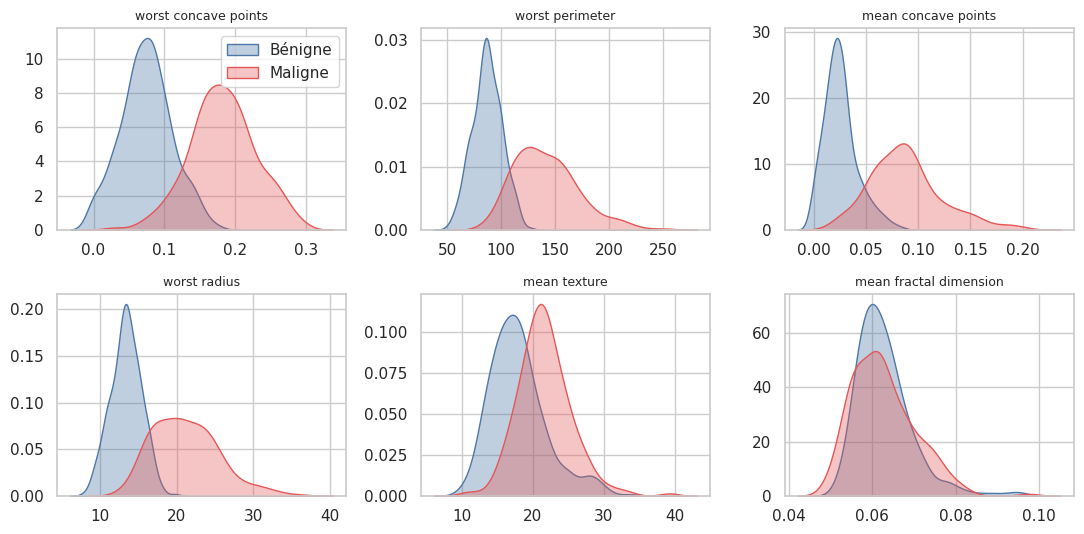

In [ ]:

auc_par_variable = {}
for colonne in X.columns:
    auc = roc_auc_score(y, X[colonne])
    if auc < 0.5:
        auc = 1 - auc
    auc_par_variable[colonne] = auc

auc_par_variable = pd.Series(auc_par_variable).sort_values(ascending=False)

print("Les 8 meilleures variables :")
print(auc_par_variable.head(8).round(3))
print("\nLes 5 moins utiles :")
print(auc_par_variable.tail(5).round(3))

variables = ["worst concave points", "worst perimeter", "mean concave points",
             "worst radius", "mean texture", "mean fractal dimension"]
plt.figure(figsize=(11, 5.5))
for i, colonne in enumerate(variables):
    plt.subplot(2, 3, i + 1)
    sns.kdeplot(X.loc[y == 0, colonne], label="Bénigne", color="#4C78A8", fill=True, alpha=0.35)
    sns.kdeplot(X.loc[y == 1, colonne], label="Maligne", color="#E45756", fill=True, alpha=0.35)
    plt.title(colonne, fontsize=9)
    plt.xlabel(""); plt.ylabel("")
    if i == 0:
        plt.legend()
plt.tight_layout()
plt.show()

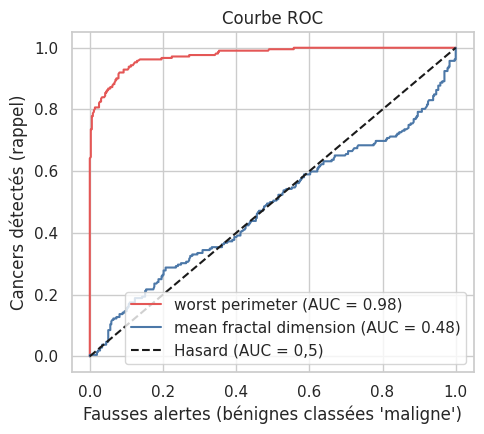

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(5, 4.5))

for colonne, couleur in [("worst perimeter", "#E45756"), ("mean fractal dimension", "#4C78A8")]:
    fpr, tpr, seuils = roc_curve(y, X[colonne])          # un point de la courbe pour chaque seuil possible
    auc = roc_auc_score(y, X[colonne])
    plt.plot(fpr, tpr, color=couleur, label=f"{colonne} (AUC = {auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Hasard (AUC = 0,5)")   # la diagonale
plt.xlabel("Fausses alertes (bénignes classées 'maligne')")
plt.ylabel("Cancers détectés (rappel)")
plt.title("Courbe ROC")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

les meuilleurs variables sont liés à la taille et les creux du tumeur,
Mais une variable peu utile seule peut l'être en combinaison avec d'autres, donc on ne supprime aucune variable pour l'instant

AUC =0.97 avec une seule variable (par exp worst perimer)

on sait que le noyau des cancers sont plus gros et avec des creux

* corrélation des variables

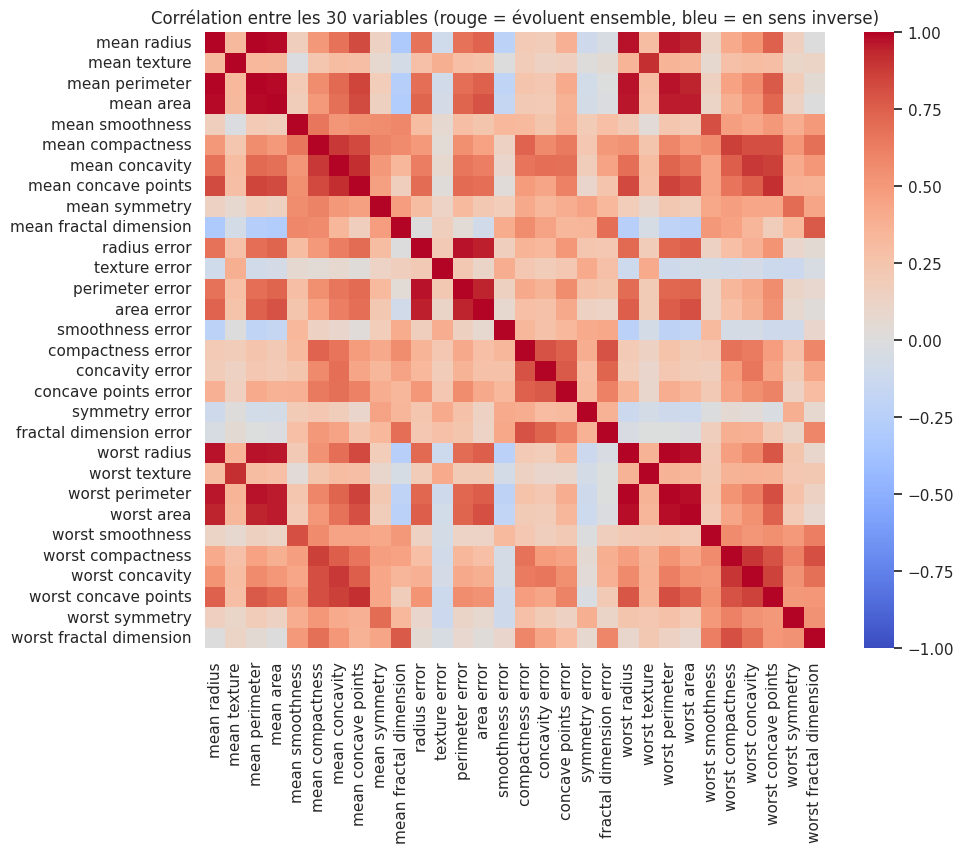

Nombre de paires au total        : 435
Paires avec corrélation > 0,9    : 21
Paires avec corrélation > 0,95   : 15

Les 5 paires les plus liées :
mean radius     mean perimeter     0.998
worst radius    worst perimeter    0.994
mean radius     mean area          0.987
mean perimeter  mean area          0.987
worst radius    worst area         0.984
dtype: float64

Variables avec VIF > 10 : 23 sur 30

Les 5 variables les plus redondantes :
mean radius        3806.0
mean perimeter     3786.0
worst radius        799.0
worst perimeter     405.0
mean area           348.0
dtype: float64


In [ ]:
# --- 1) Matrice de corrélation ---
corr = X.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Corrélation entre les 30 variables (rouge = évoluent ensemble, bleu = en sens inverse)")
plt.show()

# --- 2) Les paires de variables très corrélées ---
# On garde chaque paire une seule fois (triangle du haut de la matrice)
masque = np.triu(np.ones(corr.shape, dtype=bool), k=1)
paires = corr.where(masque).stack().dropna()   # une ligne par paire (A, B)
paires_abs = paires.abs().sort_values(ascending=False)

print("Nombre de paires au total        :", len(paires))
print("Paires avec corrélation > 0,9    :", (paires_abs > 0.9).sum())
print("Paires avec corrélation > 0,95   :", (paires_abs > 0.95).sum())
print("\nLes 5 paires les plus liées :")
print(paires_abs.head(5).round(3))

# --- 3) VIF : une variable peut-elle être "devinée" à partir des 29 autres ? ---
# VIF = 1 / (1 - R2). Si VIF > 10, la variable est très redondante.
vif = {}
for colonne in X.columns:
    autres = X.drop(columns=colonne)
    r2 = LinearRegression().fit(autres, X[colonne]).score(autres, X[colonne])
    vif[colonne] = 1 / (1 - r2)
vif = pd.Series(vif).sort_values(ascending=False)

print("\nVariables avec VIF > 10 :", (vif > 10).sum(), "sur 30")
print("\nLes 5 variables les plus redondantes :")
print(vif.head(5).round(0))